# 1. Timescales and the AR(1) model

A neural timescale is a parameter of a fitted model.  The model is usually
AR(1),

$$x_t = \varphi\, x_{t-1} + \epsilon_t$$

in which each sample is a fraction $\varphi$ of the previous sample plus white
noise.  A perturbation decays geometrically with time constant

$$\tau = \frac{-1/f_s}{\log \varphi}$$

The autocorrelation of an AR(1) process is an exponential decay with time
constant $\tau$.  Its power spectrum is a Lorentzian with a knee at
$1/(2\pi\tau)$.  Both are parameterized by $\varphi$, so an exponential fit
to the autocorrelation and a knee fit to the spectrum estimate the same
quantity.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from timescales import ARACF, ARPSD, compute_acf, compute_psd
from timescales.conversions import phi_to_tau, tau_to_phi
from timescales.sim import AR1

plt.rcParams.update({'figure.figsize': (10, 3.5), 'font.size': 11})

## Simulating a process with a known timescale

`AR1` provides the coefficient, spectrum and autocorrelation of the process it
simulates, so an estimate can be compared against the constructed value.

phi   = 0.9608
tau   = 50.0 ms
100000 samples at 500 Hz


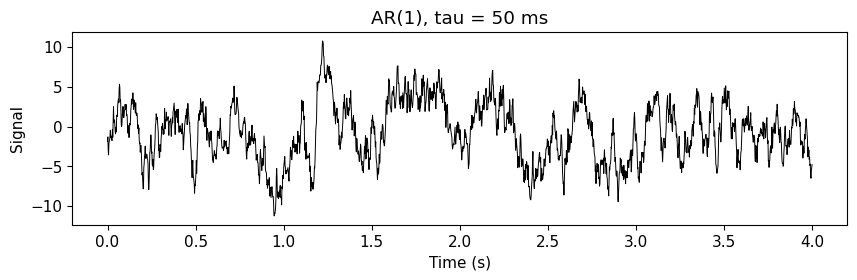

In [2]:
fs = 500.
tau_true = 0.05          # 50 ms
n_seconds = 200.

proc = AR1(tau=tau_true)
sig = proc.simulate(n_seconds, fs, np.random.default_rng(0))

print(f'phi   = {tau_to_phi(tau_true, fs):.4f}')
print(f'tau   = {phi_to_tau(tau_to_phi(tau_true, fs), fs) * 1e3:.1f} ms')
print(f'{len(sig)} samples at {fs:g} Hz')

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(np.arange(2000) / fs, sig[:2000], lw=.7, color='k')
ax.set(xlabel='Time (s)', ylabel='Signal', title='AR(1), tau = 50 ms');

## Computing a spectrum and an autocorrelation

`ARPSD` takes `(freqs, powers)` and `ARACF` takes `(lags, corrs)`.  Neither
computes its input, so any spectral or autocorrelation estimator can be used.
`compute_psd` and `compute_acf` cover the common cases.

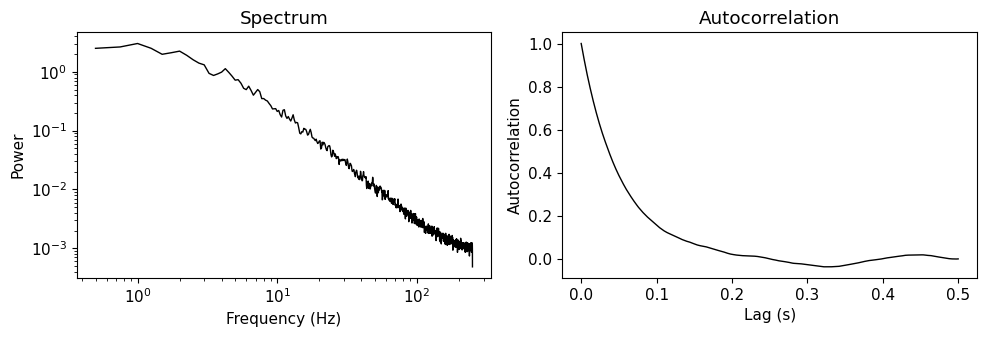

In [3]:
freqs, powers = compute_psd(sig, fs, nperseg=int(4 * fs), f_range=(0.5, 250))
lags, corrs = compute_acf(sig, nlags=250)

fig, axes = plt.subplots(1, 2)
axes[0].loglog(freqs, powers, color='k', lw=1)
axes[0].set(xlabel='Frequency (Hz)', ylabel='Power', title='Spectrum')
axes[1].plot(lags / fs, corrs, color='k', lw=1)
axes[1].set(xlabel='Lag (s)', ylabel='Autocorrelation', title='Autocorrelation')
fig.tight_layout();

## Fitting in both domains

`ARPSD` fits the spectrum and `ARACF` fits the autocorrelation.  Both default
to `order=1`.  `fs` is required to convert a fitted pole to a time constant.

In [4]:
ar_psd = ARPSD(order=1, fs=fs).fit(freqs, powers)
ar_acf = ARACF(order=1, fs=fs).fit(lags, corrs)

print(f'true       {tau_true * 1e3:6.1f} ms')
print(f'ARPSD      {ar_psd.tau * 1e3:6.1f} ms   (R^2 = {ar_psd.rsq:.4f})')
print(f'ARACF      {ar_acf.tau * 1e3:6.1f} ms   (R^2 = {ar_acf.rsq:.4f})')

true         50.0 ms
ARPSD        50.5 ms   (R^2 = 0.9954)
ARACF        55.5 ms   (R^2 = 0.9950)


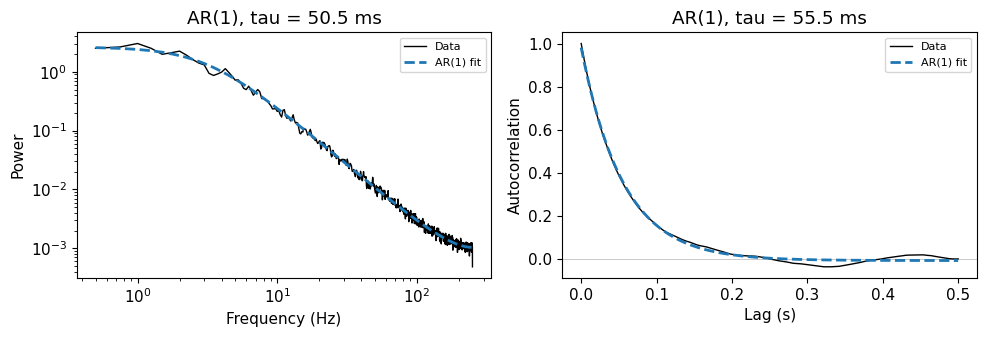

In [5]:
fig, axes = plt.subplots(1, 2)
ar_psd.plot(ax=axes[0])
ar_acf.plot(ax=axes[1])
fig.tight_layout();

Both estimates are within 12% of the constructed 50 ms.

## Fitted attributes

The fitted object holds the coefficients, the selected order, the
decomposition and the goodness of fit.

In [6]:
print('phi           ', ar_psd.phi)
print('order         ', ar_psd.order_)
print('stationary    ', ar_psd.is_stationary)
print('tau           ', f'{ar_psd.tau * 1e3:.1f} ms')
print('R^2 (log power)', f'{ar_psd.rsq:.4f}')
print('RMSE          ', f'{ar_psd.rmse:.4f}')

phi            [0.96119267]
order          1
stationary     True
tau            50.5 ms
R^2 (log power) 0.9954
RMSE           0.0481


`predict` evaluates the fitted model at arbitrary frequencies.

In [7]:
other = np.logspace(np.log10(0.5), np.log10(250), 60)
model = ar_psd.predict(other)
print(f'model power at 1 Hz:   {ar_psd.predict(np.array([1.0]))[0]:.4g}')
print(f'evaluated on {len(other)} new frequencies: {model.shape}')

model power at 1 Hz:   2.4
evaluated on 60 new frequencies: (60,)


## Recording duration

$\tau$ is estimated from the decorrelation observed within the recording.  A
recording shorter than a few hundred multiples of $\tau$ gives a variable
estimate.

In [8]:
rng = np.random.default_rng(1)
for duration in (2., 10., 100.):
    taus = []
    for _ in range(30):
        s = AR1(tau=tau_true).simulate(duration, fs, rng)
        f, p = compute_psd(s, fs, nperseg=int(min(duration, 4) * fs))
        keep = (f > 0.5) & (f <= 250)
        taus.append(ARPSD(order=1, fs=fs).fit(f[keep], p[keep]).tau)
    taus = np.array(taus) * 1e3
    print(f'T = {duration:5.0f} s ({duration / tau_true:5.0f} tau): '
          f'median {np.median(taus):6.1f} ms, 10-90% {np.percentile(taus, 10):.0f}-'
          f'{np.percentile(taus, 90):.0f} ms')

T =     2 s (   40 tau): median   59.2 ms, 10-90% 34-110 ms


T =    10 s (  200 tau): median   49.5 ms, 10-90% 41-60 ms


T =   100 s ( 2000 tau): median   50.3 ms, 10-90% 47-53 ms


`timescales.finite` gives the asymptotic moments of an AR(1) timescale: a
relative bias of $-2\tau/T$ and a relative standard error of
$\sqrt{2\tau/T}$, where $T$ is the recording duration.  A 10% standard error
requires $T = 200\tau$.

In [9]:
from timescales.finite import duration_for_relative_sd, relative_sd_asymptotic

for ratio in (20, 200, 2000):
    print(f'T = {ratio:5d} tau  ->  relative SD {relative_sd_asymptotic(ratio):.2f}')
print(f'\n10% standard error on a 50 ms timescale needs '
      f'{duration_for_relative_sd(0.05, 0.1):.0f} s')

T =    20 tau  ->  relative SD 0.32
T =   200 tau  ->  relative SD 0.10
T =  2000 tau  ->  relative SD 0.03

10% standard error on a 50 ms timescale needs 10 s


AR(1) models the autocorrelation as a single exponential and the spectrum as
a single bend.  Tutorial 2 covers higher orders.